In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
payment_df = pd.read_csv("/content/drive/MyDrive/Data science project/Fraud Detection/DS DATA.csv")

In [4]:
payment_df.head()

,accountAgeDays,numItems,localTime,paymentMethod,paymentMethodAgeDays,Category,isWeekend,label
0,29,1,4.745402,paypal,28.204861,shopping,0.0,0
1,725,1,4.742303,storecredit,0.000000,electronics,0.0,0
2,845,1,4.921318,creditcard,0.000000,food,1.0,0
3,503,1,4.886641,creditcard,0.000000,electronics,1.0,0
4,2000,1,5.040929,creditcard,0.000000,shopping,0.0,0


In [5]:
payment_df.isnull().sum()

,0
accountAgeDays,0
numItems,0
localTime,0
paymentMethod,0
paymentMethodAgeDays,0
Category,95
isWeekend,560
label,0


In [6]:
payment_df.duplicated().sum()


np.int64(3033)

In [7]:
payment_df.shape


(39221, 8)

The missing values will be handled during preprocessing
lets check the duplicates if they are legitimate. Since there is no unique identifier a customer could have made 2 similar transanctions within the same time. So it is better to investigate it before removing about 10% of the data.

In [8]:
duplicate_records = payment_df[payment_df.duplicated(keep=False)]

In [9]:
duplicate_records.shape

(4229, 8)

Comparing the distribution of fraudulent transactions in the duplicated rows vs original dataset


In [10]:
duplicate_records['label'].value_counts(normalize=True)*100

,proportion
label,
0,93.899267
1,6.100733


In [11]:
payment_df['label'].value_counts(normalize=True)*100

,proportion
label,
0,98.572193
1,1.427807


Observation:
- Approximately 3,033 additional duplicate records were identified.
- Fraud accounts for approximately 6% of the duplicate records, compared with approximately 1.5% in the original dataset.
- Therefore, the duplicate group has a higher proportion of fraudulent transactions.
Limitation:
- The dataset has no unique transaction identifier.
- The Local Time unit is undefined.
- We cannot establish whether identical rows represent separate genuine transactions or accidental duplicate entries.
Decision:
Retain duplicates
We will retain the duplicate records because removing them without sufficient evidence could eliminate genuine transactions and disproportionately affect fraudulent transactions.

In [12]:
payment_df.describe()

,accountAgeDays,numItems,localTime,paymentMethodAgeDays,isWeekend,label
count,39221.000000,39221.000000,39221.000000,39221.000000,38661.000000,39221.000000
mean,857.563984,1.084751,4.748232,122.641326,0.499547,0.014278
std,804.788212,0.566899,0.389360,283.569177,0.500006,0.118636
min,1.000000,1.000000,0.421214,0.000000,0.000000,0.000000
25%,72.000000,1.000000,4.742303,0.000000,0.000000,0.000000
50%,603.000000,1.000000,4.886641,0.012500,0.000000,0.000000
75%,1804.000000,1.000000,4.962055,87.510417,1.000000,0.000000
max,2000.000000,29.000000,5.040929,1999.580556,1.000000,1.000000


In [13]:
payment_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39221 entries, 0 to 39220
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   accountAgeDays        39221 non-null  int64  
 1   numItems              39221 non-null  int64  
 2   localTime             39221 non-null  float64
 3   paymentMethod         39221 non-null  object 
 4   paymentMethodAgeDays  39221 non-null  float64
 5   Category              39126 non-null  object 
 6   isWeekend             38661 non-null  float64
 7   label                 39221 non-null  int64  
dtypes: float64(3), int64(3), object(2)
memory usage: 2.4+ MB


#**EDA**

In [14]:
payment_df['localTime'].describe()

,localTime
count,39221.000000
mean,4.748232
std,0.389360
min,0.421214
25%,4.742303
50%,4.886641
75%,4.962055
max,5.040929


In [15]:
payment_df['localTime'].nunique()

25

In [16]:
payment_df['localTime'].value_counts().sort_index()

,count
localTime,
0.421214,2
2.596228,213
2.948940,228
3.066058,264
3.483951,365
3.575983,443
3.954522,646
4.057414,1088
4.461622,1083


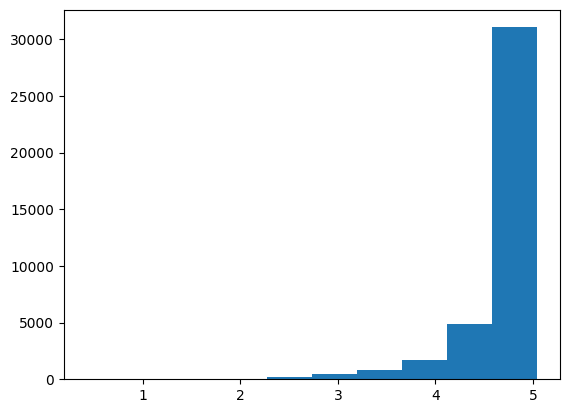

In [17]:
plt.hist(payment_df['localTime'])
plt.show()

still unable to interpret the time format

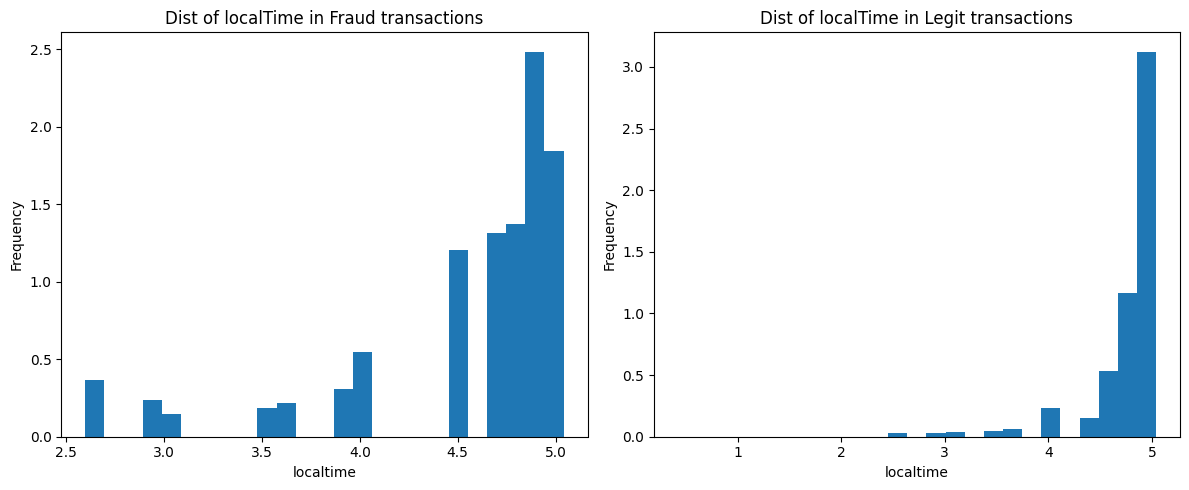

In [18]:
fraud = payment_df[payment_df['label']==1]
legit = payment_df[payment_df['label']==0]

fig, axes= plt.subplots(1, 2, figsize=(12,5))

axes[0].hist(fraud['localTime'],bins=25,density=True)
axes[0].set_title('Dist of localTime in Fraud transactions')
axes[0].set_xlabel('localtime')
axes[0].set_ylabel('Frequency')

axes[1].hist(legit['localTime'],bins=25,density=True)
axes[1].set_title('Dist of localTime in Legit transactions')
axes[1].set_xlabel('localtime')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

No distinct pattern could be found

In [19]:
fraud.describe()

,accountAgeDays,numItems,localTime,paymentMethodAgeDays,isWeekend,label
count,560.0,560.000000,560.000000,560.000000,0.0,560.0
mean,1.0,1.264286,4.555726,0.012476,NaN,1.0
std,0.0,0.706329,0.610253,0.081981,NaN,0.0
min,1.0,1.000000,2.596228,0.000000,NaN,1.0
25%,1.0,1.000000,4.505662,0.000000,NaN,1.0
50%,1.0,1.000000,4.748314,0.000000,NaN,1.0
75%,1.0,1.000000,4.921318,0.001389,NaN,1.0
max,1.0,10.000000,5.040929,0.991667,NaN,1.0


In [20]:
legit.describe()

,accountAgeDays,numItems,localTime,paymentMethodAgeDays,isWeekend,label
count,38661.000000,38661.000000,38661.000000,38661.000000,38661.000000,38661.0
mean,869.971211,1.082150,4.751020,124.417591,0.499547,0.0
std,803.917989,0.564218,0.384536,285.228464,0.500006,0.0
min,2.000000,1.000000,0.421214,0.000000,0.000000,0.0
25%,81.000000,1.000000,4.745402,0.000000,0.000000,0.0
50%,625.000000,1.000000,4.886641,0.017361,0.000000,0.0
75%,1826.000000,1.000000,4.962055,90.713194,1.000000,0.0
max,2000.000000,29.000000,5.040929,1999.580556,1.000000,0.0


Observations:
numItems and localTime are inconclusive.
AccountAgeDays, paymentMethodAgeDays, isWeekend show significant difference between fraud and legit transactions.


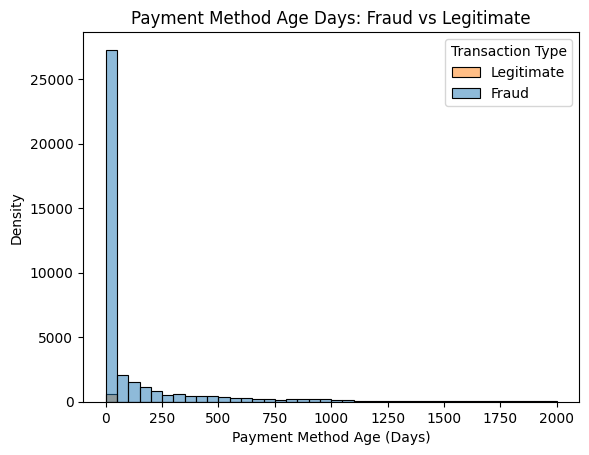

In [21]:
# Investigating  paymentMethodAgeDays
sns.histplot(data=payment_df,x='paymentMethodAgeDays',hue='label',bins=40,multiple='layer',alpha=0.5)
plt.title('Payment Method Age Days: Fraud vs Legitimate')
plt.xlabel('Payment Method Age (Days)')
plt.ylabel('Density')
plt.legend(title='Transaction Type', labels=['Legitimate', 'Fraud'])
plt.show()

Text(0.5, 1.0, 'Payment Method Age: Fraud vs Legitimate')

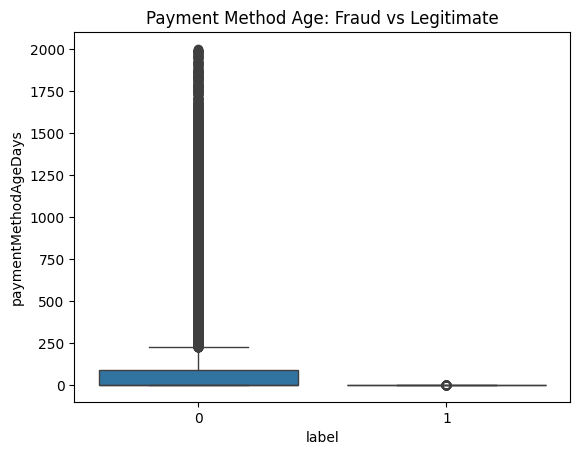

In [22]:
sns.boxplot(data=payment_df,x='label',y='paymentMethodAgeDays')
plt.title('Payment Method Age: Fraud vs Legitimate')

In [23]:
payment_df.groupby('label')['paymentMethodAgeDays'].apply(
    lambda x: (x < 1).mean() * 100
)

,paymentMethodAgeDays
label,
0,55.844391
1,100.000000


More than half of legitimate transactions also use payment methods that are less than one day old.



Every fraudulent transaction in this dataset has a payment method age below one day.

Business observation: All fraudulent transactions have payment method ages below one day. However, approximately 55.84% of legitimate transactions also fall into this category.

Business interpretation: Newly added payment methods may be associated with increased fraud risk, but their presence alone is insufficient to identify fraudulent transactions.

ML decision: Retain paymentMethodAgeDays as a candidate feature and evaluate its contribution alongside other features.

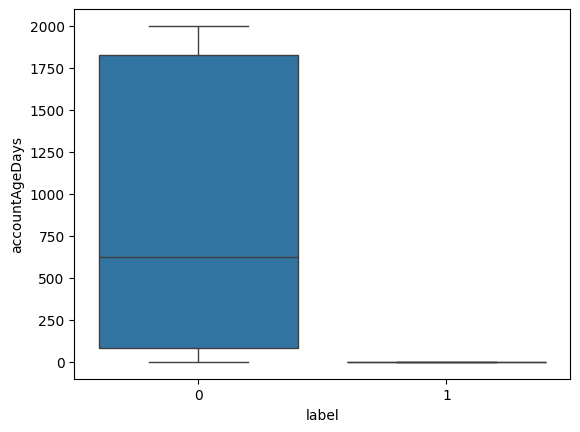

In [24]:
sns.boxplot(data=payment_df,y='accountAgeDays',x='label')
plt.show()

In [25]:
payment_df.groupby('label')['accountAgeDays'].apply(lambda x:(x==1).mean()*100)

,accountAgeDays
label,
0,0.0
1,100.0


Every fraudulent transaction has an account age of one day.



No legitimate transaction has an account age of one day.

In [26]:
payment_df['isWeekend'].unique()

array([ 0.,  1., nan])

In [27]:
payment_df.groupby('label')['isWeekend'].unique()

,isWeekend
label,
0,"[0.0, 1.0]"
1,[nan]


In [28]:
payment_df.groupby('label')['isWeekend'].value_counts(dropna=False)

label  isWeekend
0      0.0          19348
       1.0          19313
1      NaN            560
Name: count, dtype: int64

"isWeekend was excluded because the feature is missing for all fraudulent transactions. Since its relationship with fraud cannot be evaluated using the available data, retaining it would not provide reliable predictive information."

In [29]:
payment_info_df=payment_df.drop(columns='isWeekend').copy()

Analysing the Categorical Columns

In [30]:
payment_info_df['paymentMethod'].nunique()

3

In [31]:
pd.crosstab(payment_info_df['paymentMethod'],payment_info_df['label'])

label,0,1
paymentMethod,,
creditcard,27594,410
paypal,9174,129
storecredit,1893,21


In [32]:
pd.crosstab(payment_info_df['paymentMethod'],payment_info_df['label'],normalize='index')*100

label,0,1
paymentMethod,,
creditcard,98.535923,1.464077
paypal,98.613351,1.386649
storecredit,98.902821,1.097179


Payment method does not appear to have a strong association with fraud in this dataset. Store credit has a slightly lower observed fraud rate, but the differences are small.

In [33]:
pd.crosstab(payment_info_df['Category'],payment_info_df['label'])

label,0,1
Category,,
electronics,12658,176
food,12787,177
shopping,13129,199


In [34]:
pd.crosstab(payment_info_df['Category'],payment_info_df['label'],normalize=True)*100

label,0,1
Category,,
electronics,32.351889,0.449829
food,32.681593,0.452385
shopping,33.555692,0.508613


Product category does not show a substantial difference in observed fraud rates. Shopping has a slightly higher fraud percentage, but the difference is small.

In [35]:
payment_info_df[payment_info_df['Category'].isna()]['label'].value_counts()

,count
label,
0,87
1,8


category – no substantial difference in fraud rates; 95 missing values to handle.


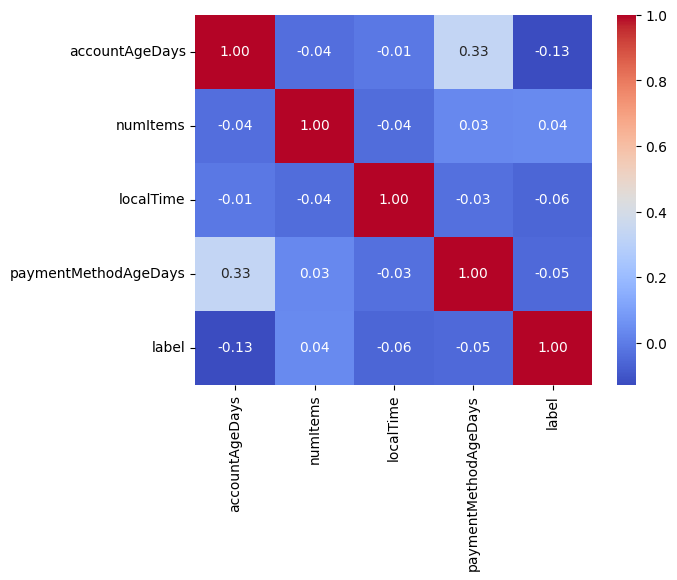

In [36]:
correlation = payment_info_df.select_dtypes(include='number').corr()
sns.heatmap(correlation,cmap='coolwarm',fmt='.2f',annot=True,)

plt.show()


We haven't identified strong linear relationships among the numerical features. There is no obvious multicollinearity concern from the correlations we examined.

#**Feature** **Engineering**

In [37]:
payment_info_df.head()

,accountAgeDays,numItems,localTime,paymentMethod,paymentMethodAgeDays,Category,label
0,29,1,4.745402,paypal,28.204861,shopping,0
1,725,1,4.742303,storecredit,0.000000,electronics,0
2,845,1,4.921318,creditcard,0.000000,food,0
3,503,1,4.886641,creditcard,0.000000,electronics,0
4,2000,1,5.040929,creditcard,0.000000,shopping,0


In [38]:
payment_info_df['Category'].nunique()

3

In [39]:
payment_info_df['paymentMethod'].nunique()

3

In [40]:
payment_info_df['Category'] = payment_info_df['Category'].fillna('Unknown')

In [41]:
payment_info_df = pd.get_dummies(
    payment_info_df,
    columns=['paymentMethod', 'Category'],
    dtype=int
)

In [42]:
payment_info_df.head()

,accountAgeDays,numItems,localTime,paymentMethodAgeDays,label,paymentMethod_creditcard,paymentMethod_paypal,paymentMethod_storecredit,Category_Unknown,Category_electronics,Category_food,Category_shopping
0,29,1,4.745402,28.204861,0,0,1,0,0,0,0,1
1,725,1,4.742303,0.000000,0,0,0,1,0,1,0,0
2,845,1,4.921318,0.000000,0,1,0,0,0,0,1,0
3,503,1,4.886641,0.000000,0,1,0,0,0,1,0,0
4,2000,1,5.040929,0.000000,0,1,0,0,0,0,0,1


#**Model** **Building**

In [43]:
from sklearn.model_selection import train_test_split

X = payment_info_df.drop(columns='label')
Y = payment_info_df['label']

# stratified split to maintain the same proportion of fraud transactions during split
X_train,X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2,random_state=42, stratify = Y)

In [44]:
Y_test.value_counts()

,count
label,
0,7733
1,112


In [45]:
Y_train.value_counts()

,count
label,
0,30928
1,448


In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, class_weight='balanced')

rf_model.fit(X_train,Y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [48]:
y_pred_rf = rf_model.predict(X_test)

In [49]:
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [50]:
from sklearn.metrics import confusion_matrix,classification_report

cm_rf = confusion_matrix(Y_test,y_pred_rf)
print(cm_rf)

[[7733    0]
 [   0  112]]


In [51]:
print(classification_report(Y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7733
           1       1.00      1.00      1.00       112

    accuracy                           1.00      7845
   macro avg       1.00      1.00      1.00      7845
weighted avg       1.00      1.00      1.00      7845



The Random Forest might have discovered this simple rule:
If accountAgeDays equals 1, predict fraud. Otherwise, predict legitimate.

In [52]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance.sort_values(
    by='Importance',
    ascending=False
)

,Feature,Importance
0,accountAgeDays,0.805614
3,paymentMethodAgeDays,0.152724
2,localTime,0.021484
1,numItems,0.015780
9,Category_food,0.000770
8,Category_electronics,0.000734
10,Category_shopping,0.000681
6,paymentMethod_storecredit,0.000667
4,paymentMethod_creditcard,0.000592
5,paymentMethod_paypal,0.000524


In [53]:
y_pred_account = (X_test['accountAgeDays'] == 1).astype(int)

print(confusion_matrix(Y_test, y_pred_account))

[[7733    0]
 [   0  112]]


XGBOOST

In [54]:
scale_pos_weight = (Y_train == 0).sum() / (Y_train == 1).sum()

print(scale_pos_weight)

69.03571428571429


In [55]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=69.04,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [56]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [58]:
print(confusion_matrix(Y_test, y_pred_xgb))

[[7733    0]
 [   0  112]]


In [60]:
print(classification_report(Y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7733
           1       1.00      1.00      1.00       112

    accuracy                           1.00      7845
   macro avg       1.00      1.00      1.00      7845
weighted avg       1.00      1.00      1.00      7845



Again 100% accuracy maybe due to the 'accountAgeDays' because it distinguishes fraud and legit very clearly. Lets remove it and check again.

In [61]:
X_train_no_age = X_train.drop(columns=['accountAgeDays'])
X_test_no_age = X_test.drop(columns=['accountAgeDays'])

In [66]:
rf_model_2 = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, class_weight='balanced')

rf_model_2.fit(X_train_no_age,Y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [68]:
y_pred_rf_2 = rf_model_2.predict(X_test_no_age)

In [69]:
cm_rf_2 = confusion_matrix(Y_test,y_pred_rf_2)
print(cm_rf_2)

[[6829  904]
 [  88   24]]


In [70]:
print(classification_report(Y_test,y_pred_rf_2))

              precision    recall  f1-score   support

           0       0.99      0.88      0.93      7733
           1       0.03      0.21      0.05       112

    accuracy                           0.87      7845
   macro avg       0.51      0.55      0.49      7845
weighted avg       0.97      0.87      0.92      7845



XGBOOST


In [71]:
xgb_model_2 = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    scale_pos_weight=69.04,
    random_state=42,
    eval_metric='logloss'
)

xgb_model_2.fit(X_train_no_age, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [72]:
y_pred_xgb = xgb_model_2.predict(X_test_no_age)

In [73]:
print(confusion_matrix(Y_test, y_pred_xgb))

[[5547 2186]
 [  34   78]]


In [74]:
print(classification_report(Y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.99      0.72      0.83      7733
           1       0.03      0.70      0.07       112

    accuracy                           0.72      7845
   macro avg       0.51      0.71      0.45      7845
weighted avg       0.98      0.72      0.82      7845



- Random Forest is more conservative in identifying fraud.
- XGBoost is more aggressive in identifying fraud.
Neither model is performing particularly well in terms of precision.

Logistic Regression

In [75]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ['numItems', 'localTime', 'paymentMethodAgeDays']

scaler = StandardScaler()

X_train_scaled = X_train_no_age.copy()
X_test_scaled = X_test_no_age.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_no_age[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_test_no_age[numeric_cols]
)

In [77]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_model.fit(X_train_scaled, Y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [78]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [79]:
print(confusion_matrix(Y_test, y_pred_lr))

[[4302 3431]
 [  17   95]]


In [81]:
print(classification_report(Y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.56      0.71      7733
           1       0.03      0.85      0.05       112

    accuracy                           0.56      7845
   macro avg       0.51      0.70      0.38      7845
weighted avg       0.98      0.56      0.70      7845



# Conclusion – Fraud Detection Project

The objective of this project was to identify potentially fraudulent transactions using machine learning classification algorithms.

Exploratory data analysis revealed a significant class imbalance, with fraudulent transactions representing approximately 1.4% of the dataset.

Three classification algorithms were evaluated: Random Forest, XGBoost and Logistic Regression.

Initially, all three models demonstrated perfect classification performance when the `accountAgeDays` feature was included. Further investigation revealed that all fraudulent transactions had an account age of one day, while none of the legitimate transactions had this value.

To understand the influence of this feature, the models were retrained without `accountAgeDays`. Their performance declined considerably, demonstrating the importance of this feature in the original predictions.

Among the models trained without this feature, XGBoost achieved the highest fraud-class F1-score (0.07), while Logistic Regression achieved the highest fraud recall (0.85). Random Forest had the lowest fraud recall (0.21).

The experiment demonstrated that accuracy alone is insufficient for evaluating fraud detection models, particularly when dealing with highly imbalanced datasets. Precision, recall and F1-score provide more meaningful insights into the models' ability to identify fraudulent transactions and the number of false alerts generated.

XGBoost was identified as a candidate for further investigation because of its comparatively balanced fraud-class performance. However, all three models require further improvement in precision and independent validation before real-world deployment.

The project also highlighted the importance of feature investigation, model comparison and business considerations when selecting a machine learning model.
